# PINN for CHL under clouds: results

Physics-informed runs of the dilated CNN (`chl_cnn/train_pinn.py`), 1997-2020 store, year-interleaved split, scored on the same fixed fake-cloud hidden pixels as the runs in [cnn_results.ipynb](cnn_results.ipynb). Design and sanity checks are in [pinn_design.ipynb](pinn_design.ipynb). All numbers below are on the **val** days (years 2001, 2007, 2013, 2018); test is held out until a configuration is chosen.

**Model.** Backbone of `perf_dilated_vis01` (9 physical features, CHL at t±2 with persisted donor clouds, climatology and coordinate channels, residual-to-climatology output) with a 3-channel head: ln CHL at t−1, t, t+1. 12 epochs, cosine schedule, batch 8, seed 0. Data loss = L1 on hidden pixels of day t (+0.1 × visible pixels) plus L1 on the hidden pixels of t±1.

**Physics loss.** On every ocean pixel with a full 5-point ocean stencil, finite currents and both neighbour days present, including under real clouds, after pasting observed pixels back:

$$r = \frac{\hat C_{t+1}-\hat C_{t-1}}{2\,\Delta t} + \mathbf u\cdot\nabla \hat C_t - K\nabla^2 \hat C_t - S, \qquad \text{loss} = \text{data} + \lambda\,\overline{w\,|r|}$$

upwind advection with OSCAR surface currents, $K = 500$ m² s⁻¹, $\lambda$ ramped from 0 over the first 3 epochs. Units of $r$: ln CHL per day.

| term | what it enforces | parameters |
|---|---|---|
| transport residual | the field under a cloud today is consistent with what the currents carried in from yesterday and out to tomorrow | none ($K$ fixed) |
| `--src-clim` | $S$ includes $\partial_t$ of the day-of-year climatology: the seasonal cycle is not charged to transport | none |
| `--src-ekman` | $S$ includes $\alpha \sum_k \kappa_k\, w_{E,k}^+ / h_0$: recent upwelling-favourable wind-stress curl may raise ln CHL, $\alpha \ge 0$, lag kernel $\kappa$ over 0-3 / 4-10 / 11-20 / 21-30 days; weight 0 for \|lat\| < 3°, 1 beyond 5° (Coriolis → 0 at the equator) | $\alpha$, $\kappa$ (5) |
| `--phys-weight courant` | residual weight $1/\max(1, \mathrm{Co}_{clim})$: pixels where the currents cross more than one cell per day, where the daily stencil cannot track a parcel, count less | none |

| run | λ | priors |
|---|---|---|
| `pinn_lam0` | 0 | control |
| `pinn_lam0p1`, `pinn_lam0p3`, `pinn_lam1p0` | 0.1, 0.3, 1 | transport only |
| `pinn_v1_clim`, `pinn_v1_ekman`, `pinn_v1_courant` | 0.3 | one prior each |
| `pinn_v1_clim_ekman`, `pinn_v1_all` | 0.3 | cumulative |
| `pinn_long_lam0`, `pinn_long_lam0p3`, `pinn_long_lam1p0` | 0, 0.3, 1 | 60 epochs, best-val checkpoint from epoch 10 |
| `nochl_lam0`, `nochl_lam0p3` | 0, 0.3 | **no CHL image**: 9 physical features + climatology + coordinates only, 12 epochs; data loss on all observed pixels |
| `nochl_cloud_lam0`, `nochl_cloud_lam0p3` | 0, 0.3 | as above plus the 0/1 observation masks of t, t±1, t±2 as inputs |
| `nochl_today_lam0`, `nochl_today_lam0p3` | 0, 0.3 | **no CHL image at t**, CHL context at t±1 (donor clouds persisted), physical features at t−1, t, t+1; 12 epochs |
| `unet_mtcg_lam0`, `unet_mtcg_lam0p3` | 0, 0.3 | U-Net as in the mind-the-chl-gap notebooks: 64/128/256 double-conv, inputs u/v wind, SST, air temperature, season, CHL t±1; MSE loss; 30 epochs |
| `unet_d2w64_*`, `unet_d3w32_*` | 0, 0.3 | U-Net PINNs with the full CNN-PINN input set and L1 loss, ~1.9 M params: 2-level 64/128/256 and 3-level 32/64/128/256; 30 epochs |

Reference: `perf_dilated_vis01` (data only, 30 epochs) val MAE 0.138.


In [1]:
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent
import sys; sys.path.insert(0, str(ROOT))
from chl_cnn.runs import find_run
FIG = ROOT / "analyses" / "pinn" / "figures"
FIGC = ROOT / "analyses" / "clouds" / "figures"
show = lambda p, w=1500: display(Image(filename=str(p), width=w))

## 1. λ sweep (transport residual only)

Table: val hidden-pixel scores and mean |r| under real clouds / on observed pixels. Figure: val MAE by epoch, residual by epoch, final values vs λ.

  lam  val MAE  val RMSE  val bias  |r| cloud  |r| obs  test MAE test |r| cloud  n val px n val cloud px
    0   0.1444    0.2382   -0.0120     0.0655   0.0823    0.1484         0.0718   4998642       16186210
  0.1   0.1442    0.2381   -0.0140     0.0574   0.0789    0.1484         0.0639   4998642       16186210
  0.3   0.1440    0.2389   -0.0153     0.0324   0.0678    0.1480         0.0386   4998642       16186210
    1   0.1450    0.2415   -0.0154     0.0199   0.0554    0.1490         0.0241   4998642       16186210


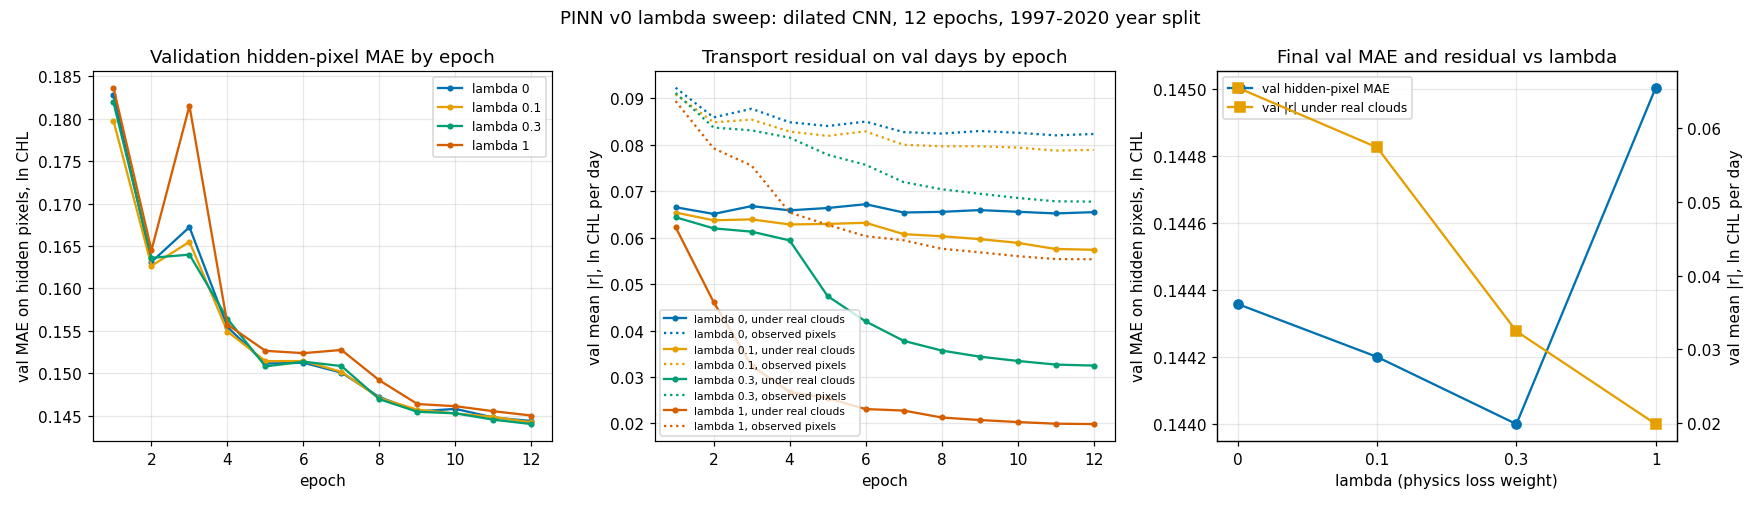

In [2]:
%run ../analyses/pinn/pinn_sweep.py
show(FIG / 'pinn_lambda_sweep.png')

**Observations.** Val MAE spread across λ is 0.001 (0.1440-0.1450), single seed. The residual under real clouds drops from 0.066 to 0.020 ln CHL/day between λ = 0 and λ = 1; on observed pixels (pasted back, only stencil neighbours can move) it drops from 0.082 to 0.055. λ = 1 has the largest RMSE (0.242 vs 0.238).

## 2. Prior-knowledge terms (λ = 0.3)

`|r_base|` is the transport-only residual, comparable across runs with different source terms. α and κ are the learned Ekman coefficient and lag kernel.

run                             val MAE  val RMSE    bias  |r| cloud  |r_base| cloud  |r| obs   alpha   kappa (0-3,4-10,11-20,21-30 d) n hidden px
no physics (lam 0)               0.1444    0.2382 -0.0120     0.0655          0.0655   0.0823       -                                -     4998642
transport only (lam 0.3)         0.1440    0.2389 -0.0153     0.0324          0.0324   0.0678       -                                -     4998642
+ seasonal source                0.1441    0.2392 -0.0158     0.0334          0.0339   0.0679       -                                -     4998642
+ Ekman source                   0.1442    0.2392 -0.0156     0.0329          0.0329   0.0682 0.00589         [0.39, 0.24, 0.22, 0.15]     4998642
+ Courant weighting              0.1441    0.2390 -0.0152     0.0342          0.0342   0.0691       -                                -     4998642
+ seasonal + Ekman               0.1443    0.2392 -0.0147     0.0335          0.0340   0.0682 0.00465         [0.36, 0

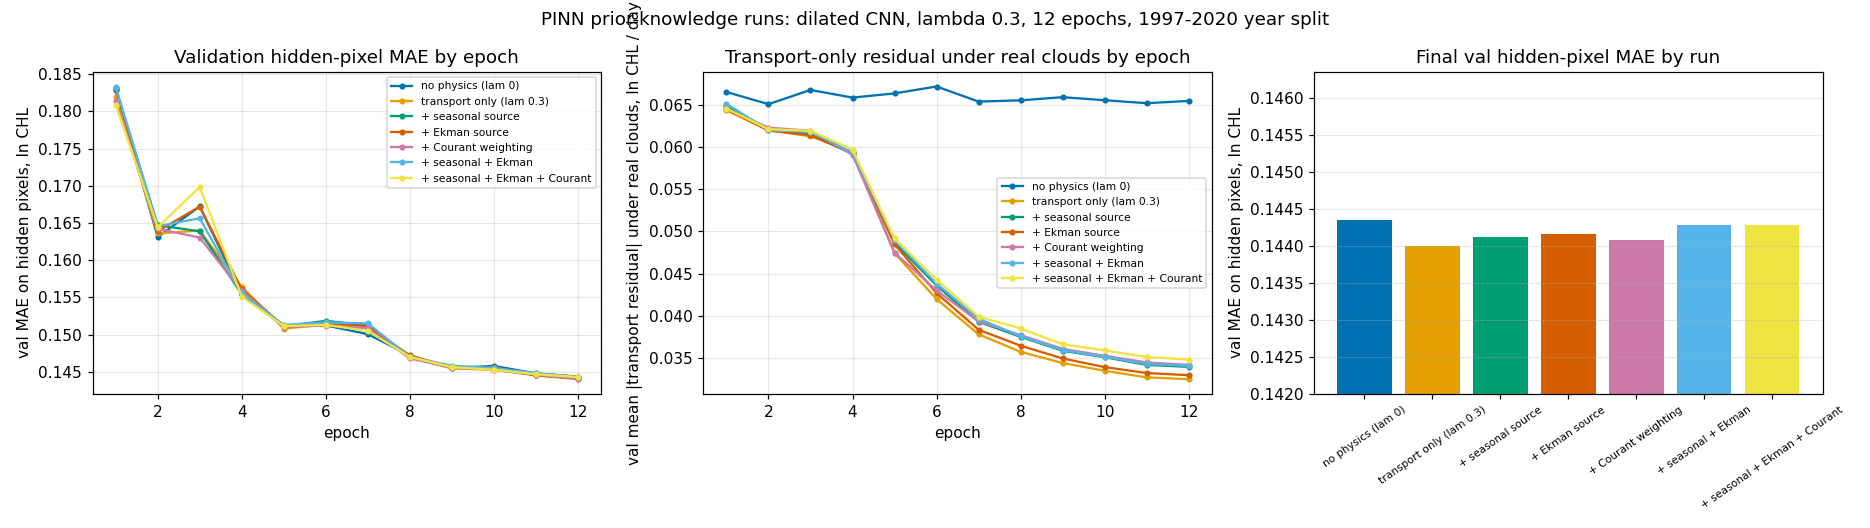

In [3]:
%run ../analyses/pinn/pinn_priors.py
show(FIG / 'pinn_priors.png')

**Observations.** All prior runs sit at val MAE 0.1441-0.1443, within the λ-sweep spread. The seasonal source has mean magnitude 0.0075 ln CHL/day over the ocean, against a residual of 0.03-0.07. The Ekman α decays monotonically from its initial 0.036 to 0.005 over 12 epochs; with mean $w_E^+ \approx 0.25$ m/day that is a source of order $4\times10^{-5}$ per day. κ ends at [0.40, 0.18, 0.18, 0.23] (0-3 day window heaviest). The Courant weight is < 1 on 63 % of ocean pixels (median $\mathrm{Co}_{clim}$ 1.18, mean weight 0.82).

## 3. Diagnostic maps at epoch 12, val day 2013-03-21

Top: input, prediction, truth, hidden-pixel error. Bottom: transport-only residual, prior source term, full residual, residual histograms. Same day for every run.

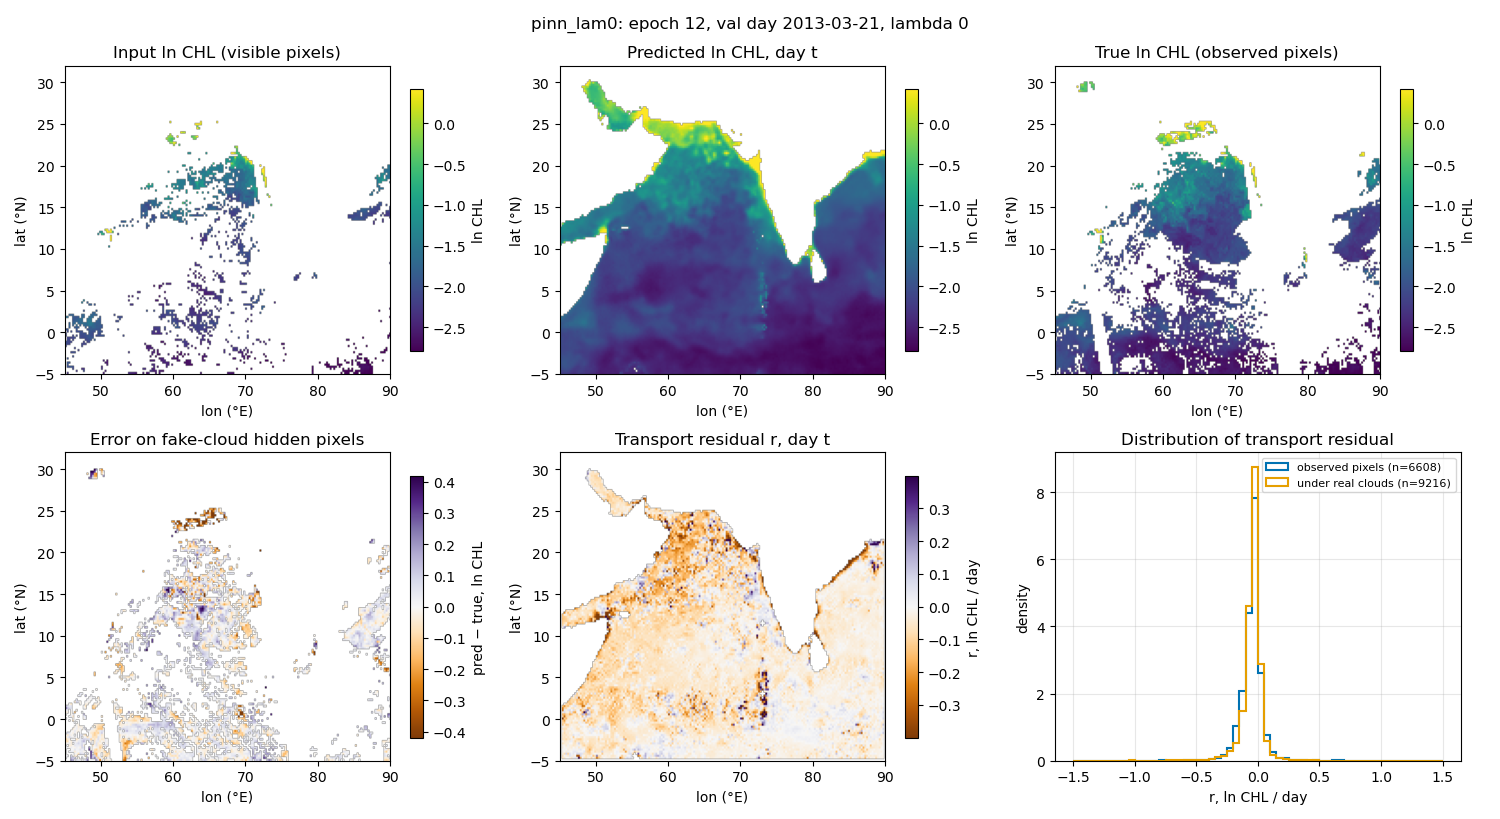

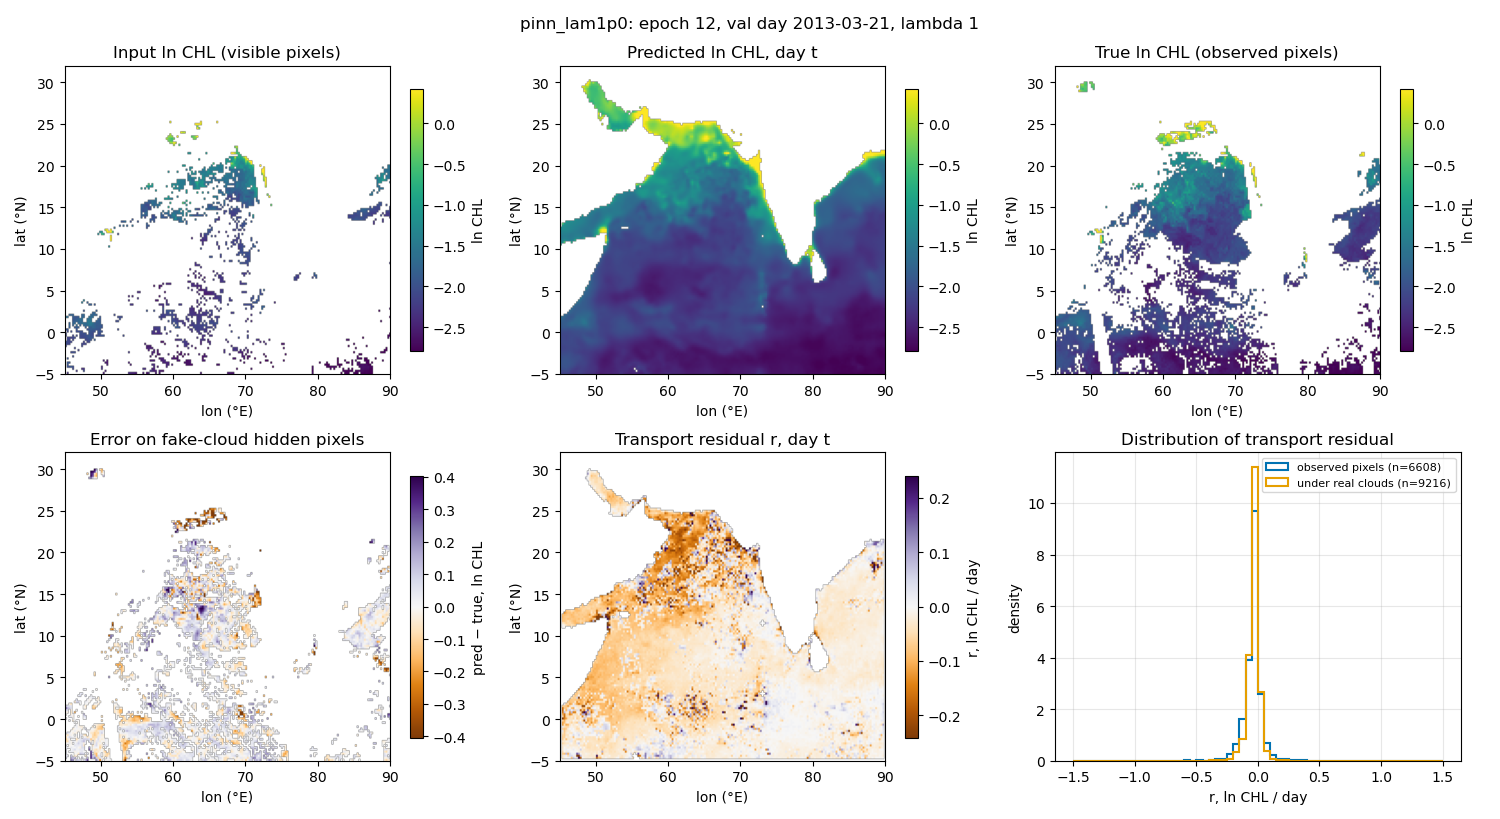

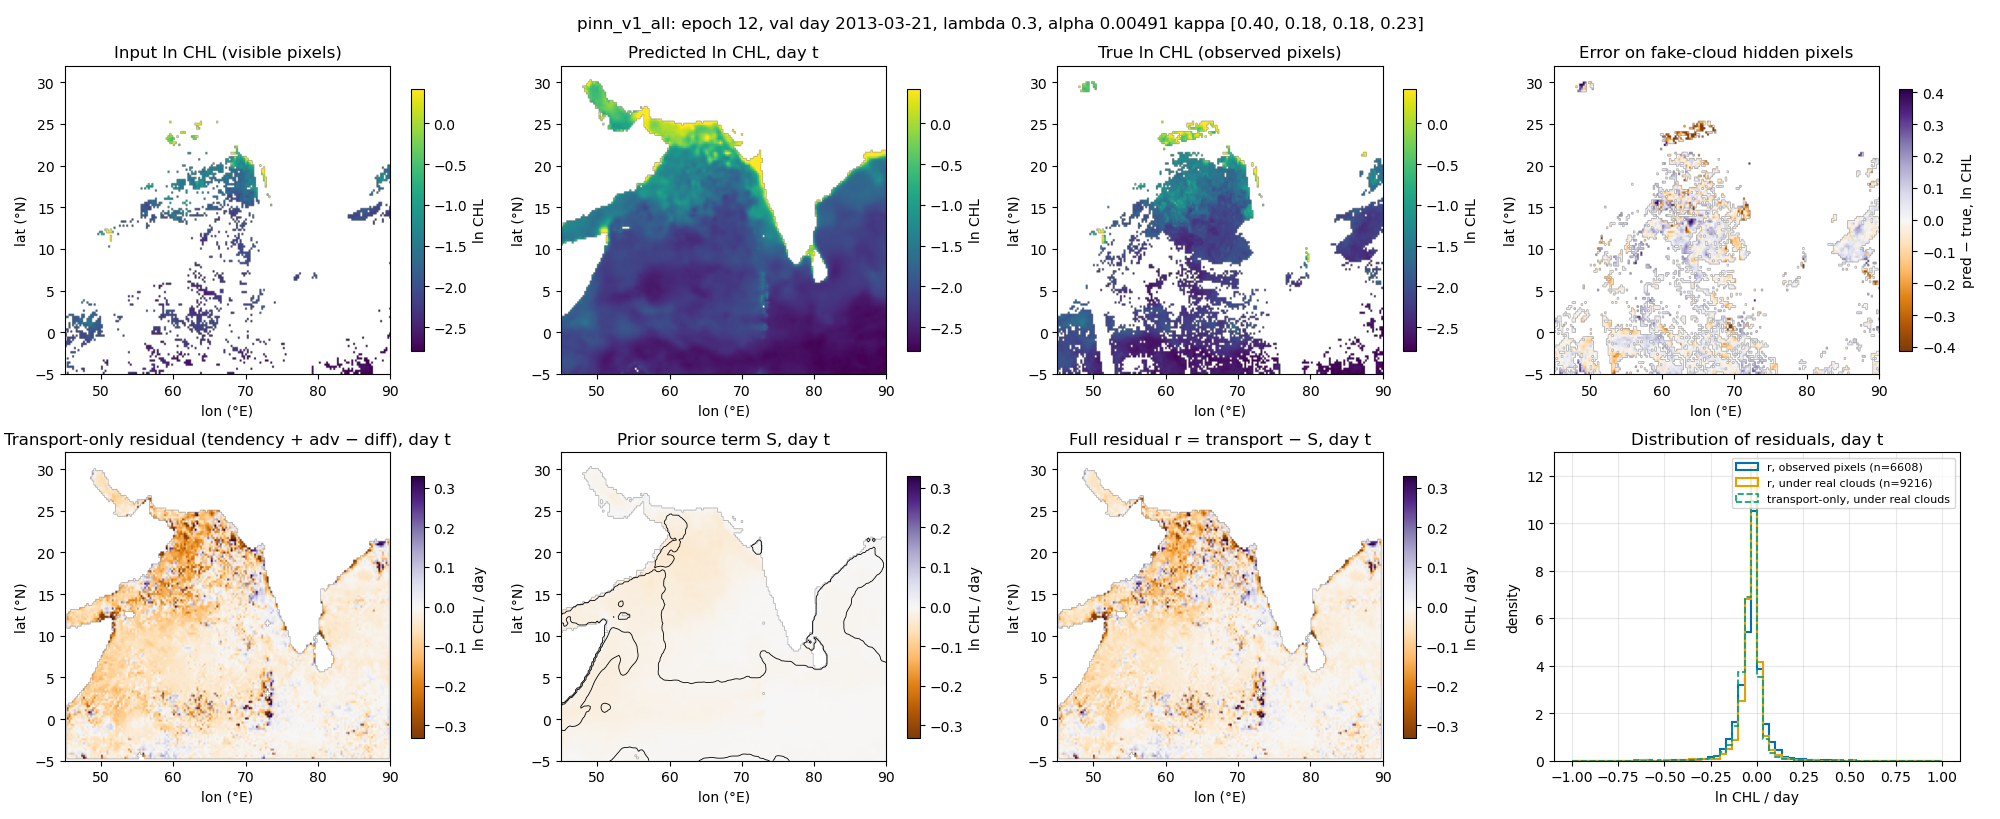

In [4]:
for r in ['pinn_lam0', 'pinn_lam1p0', 'pinn_v1_all']:
    show(find_run(r) / 'figures' / 'epoch_012.png', 1700)

**Observations.** Transport-only residual on this day is negative over most of the Arabian Sea in every run (brown in the bottom-left panel); the prior source term (bottom, second) is an order of magnitude smaller and does not change the pattern.

## 4. Does the physics change the prediction pattern? (λ = 0 vs 0.3 vs 1, val days)

From the saved full-field predictions, no retraining. Under real clouds = ocean pixels with no L3 observation on that day (70 % of ocean pixel-days on val).

1. where predictions differ: mean |pred(λ) − pred(0)|, under clouds vs observed
2. smoothness: gradient magnitude and radial power spectrum (land-free box 4.5-19.25°N, 58-72.75°E)
3. temporal coherence: |pred(t+1) − pred(t)| on pixels cloudy both days
4. does the predicted change under clouds follow the currents? Correlation per consecutive-day pair of the predicted change with the advective change (yesterday's field back-tracked one day along the currents) and with the climatological change
5. two case days with ~90 % real cloud over an upwelling box

val days 1458; ocean px 16695; mean real-cloud fraction 0.702


1. mean |pred - pred_lam0| under real clouds                 lam 0.3: 0.0507  lam 1: 0.0600
1. mean |pred - pred_lam0| on observed pixels                lam 0.3: 0.0337  lam 1: 0.0420


2. mean |grad pred| (ln CHL per 100 km) under real clouds    lam 0: 0.3218  lam 0.3: 0.2575  lam 1: 0.2395
2. mean |grad pred| (ln CHL per 100 km) on observed pixels   lam 0: 0.3395  lam 0.3: 0.3181  lam 1: 0.3109
2. mean |grad truth| on fully observed stencils              0.5721


consecutive val-day pairs: 1452
3. mean |pred_t+1 - pred_t| on pixels cloudy both days       lam 0: 0.0942  lam 0.3: 0.0882  lam 1: 0.0850
3. mean |truth_t+1 - truth_t| on pixels observed both days   0.1434
4. corr(pred change under clouds, advective change), median  lam 0: 0.0841  lam 0.3: 0.0824  lam 1: 0.0798
4. corr(pred change under clouds, climatological change), median lam 0: 0.2171  lam 0.3: 0.1735  lam 1: 0.1824
4. sd of pred change under clouds (ln CHL/day), median       lam 0: 0.1262  lam 0.3: 0.1172  lam 1: 0.1121


5. case day Somali coast (5-12N, 48-56E), July: 2001-07-25, real-cloud fraction in box 0.89, mean |pred1 - pred0| in box under clouds 0.1077
5. case day Oman coast (16-23N, 55-62E), August: 2007-08-24, real-cloud fraction in box 0.88, mean |pred1 - pred0| in box under clouds 0.1826


figures -> /mnt/custom-file-systems/s3/shared/ecology/mind_the_chl_gap/analyses/figures


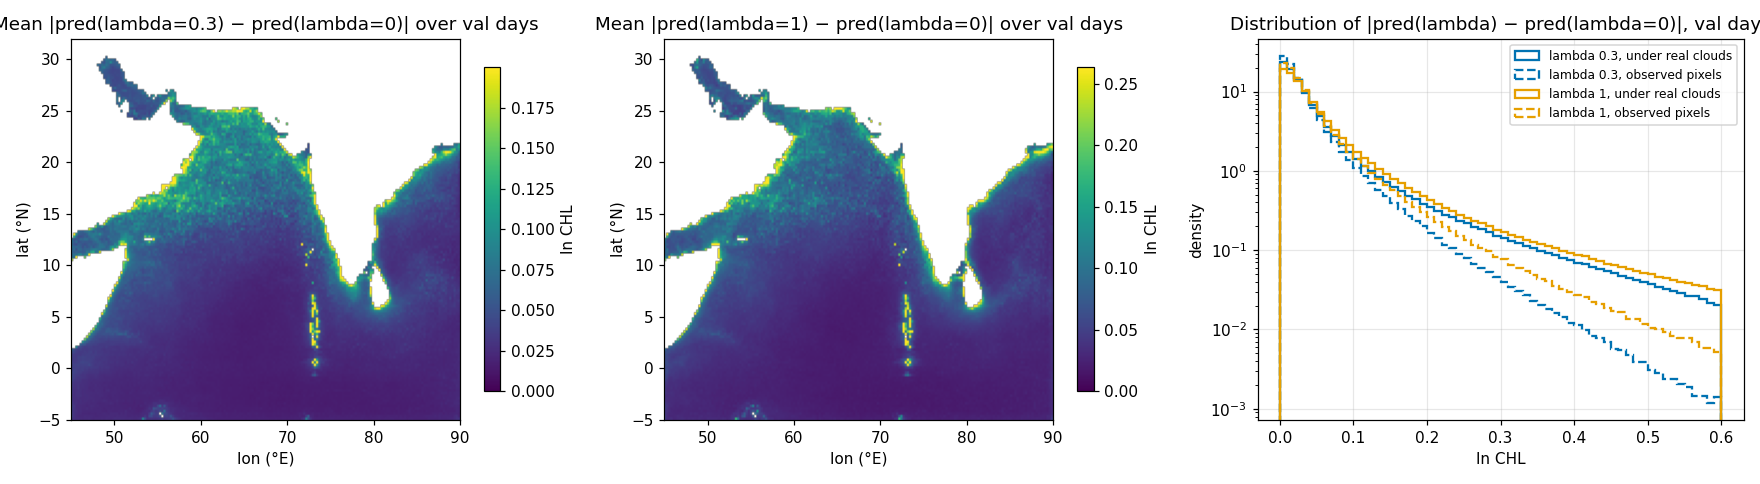

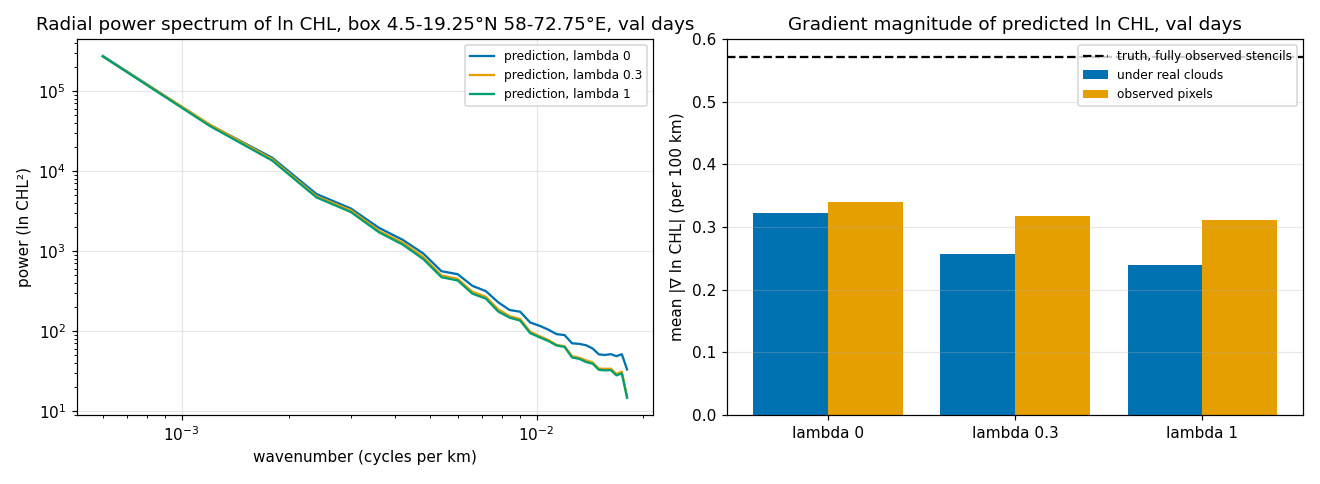

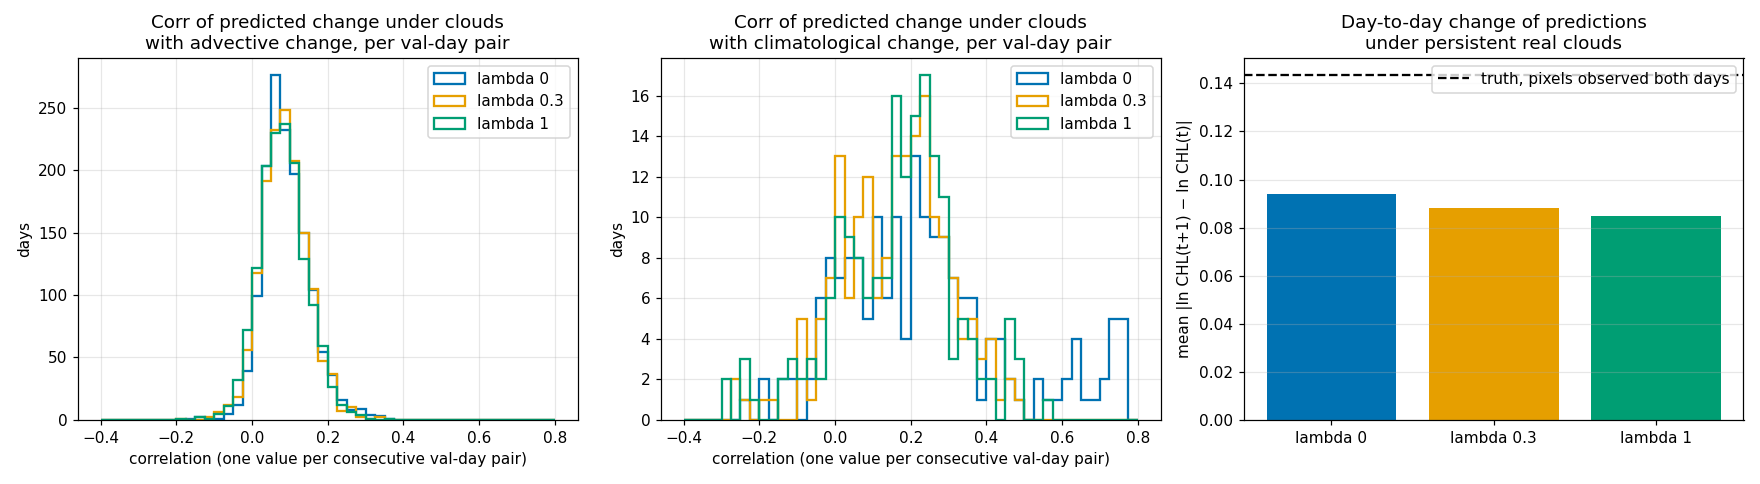

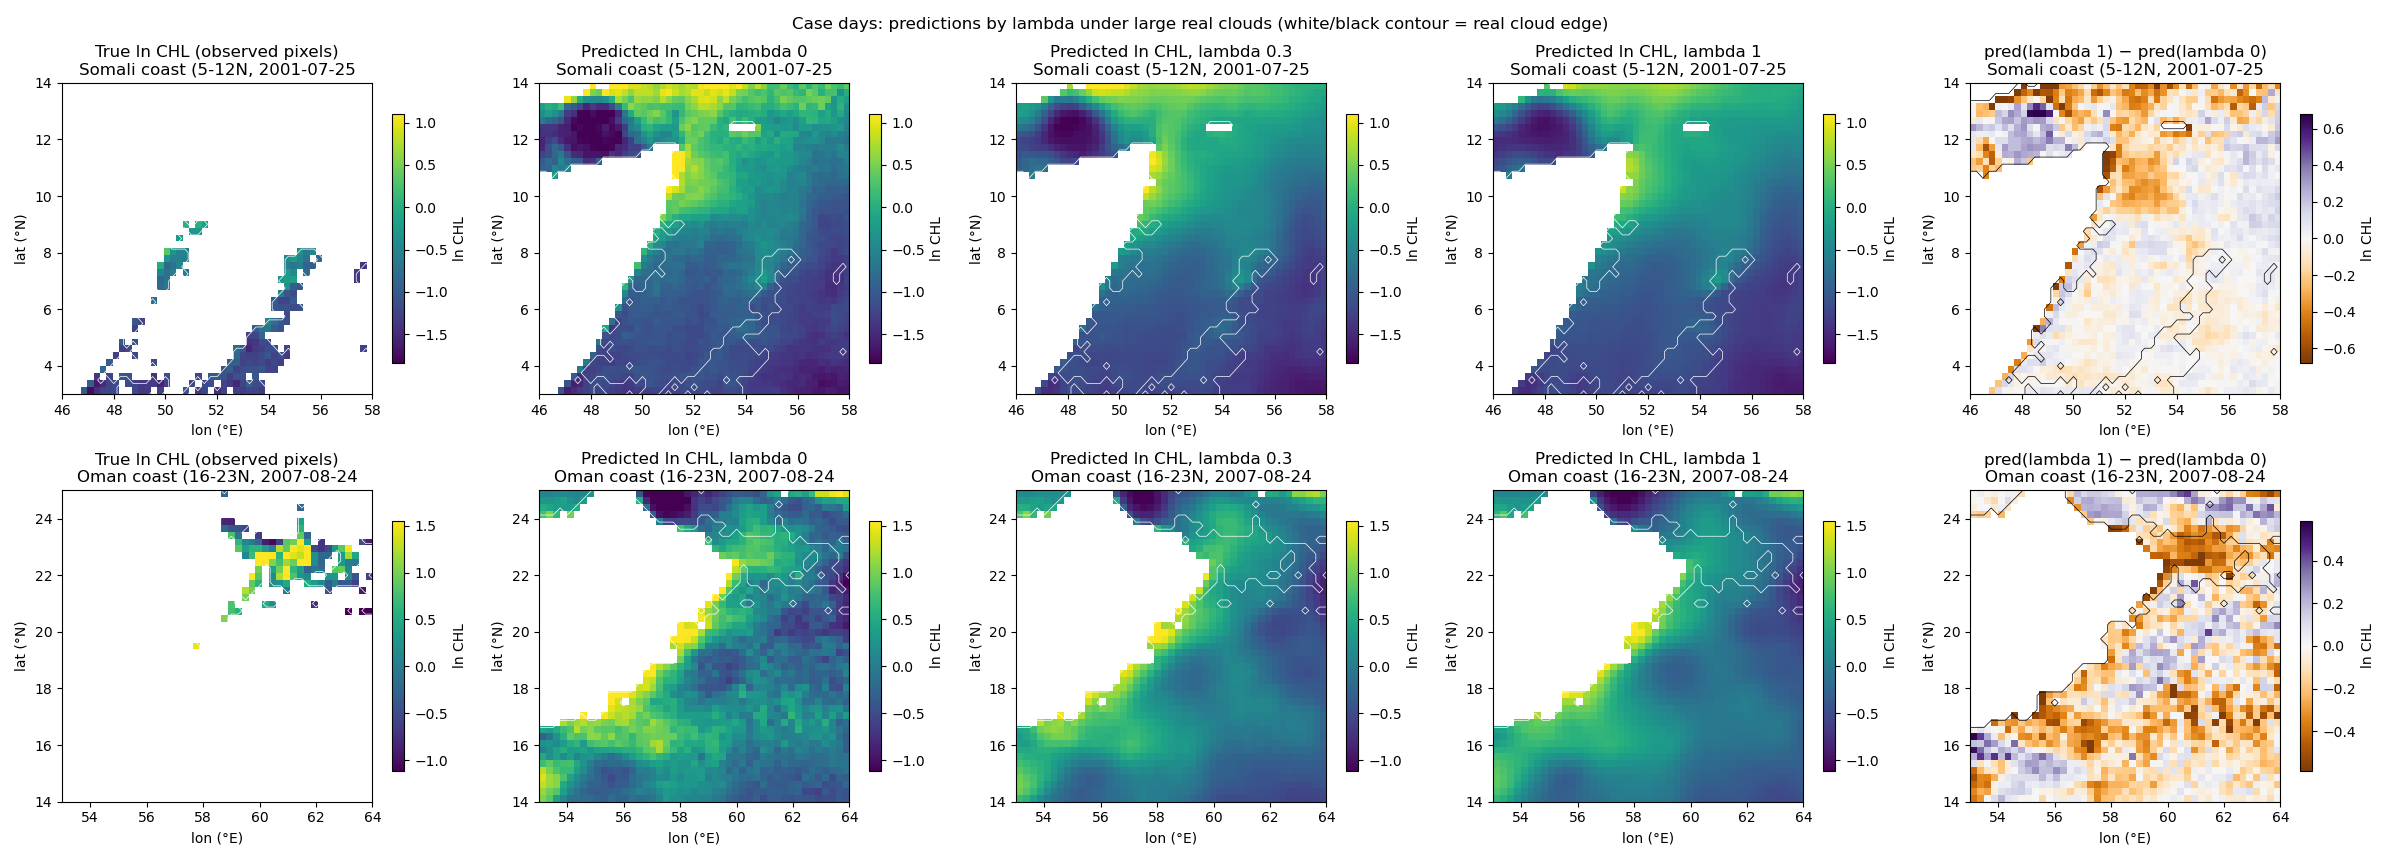

In [5]:
%run ../analyses/pinn/pinn_qualitative.py
for f in ['pinn_qual_difference', 'pinn_qual_smoothness', 'pinn_qual_temporal']:
    show(FIG / f'{f}.png')
show(FIG / 'pinn_qual_cases.png', 1800)

**Observations.**

| | λ = 0 | λ = 0.3 | λ = 1 |
|---|---|---|---|
| mean \|pred − pred(λ=0)\| under real clouds (ln CHL) | – | 0.051 | 0.060 |
| mean \|pred − pred(λ=0)\| on observed pixels | – | 0.034 | 0.042 |
| mean \|∇ ln CHL\| under real clouds (per 100 km) | 0.32 | 0.26 | 0.24 |
| mean \|∇ ln CHL\| on observed pixels | 0.34 | 0.32 | 0.31 |
| truth, fully observed stencils | 0.57 | | |
| \|pred(t+1) − pred(t)\| under persistent clouds | 0.094 | 0.088 | 0.085 |
| truth, observed both days | 0.143 | | |
| median corr(pred change, advective change) | 0.084 | 0.082 | 0.080 |
| median corr(pred change, climatological change) | 0.22 | 0.17 | 0.18 |

* The λ runs differ from the control by 0.05-0.06 ln CHL under clouds, about 40 % of the hidden-pixel MAE, and the differences concentrate in the northern Arabian Sea, along the Indian west coast and at the Maldives ridge (73°E).
* The physics term smooths: gradient magnitude under clouds falls 25 % from λ = 0 to λ = 1, and the power spectrum loses energy at scales below ~100 km. Every run is smoother than the observed field (0.57).
* The predicted day-to-day change under clouds does not follow the currents more at higher λ: the correlation with the advective change stays at 0.08. The λ = 0 control correlates more with the climatological change (0.22 vs 0.17-0.18).
* Case days: at Oman (2007-08-24) the control predicts filamentary structure under the cloud that the λ runs replace with a smooth field; at Somali (2001-07-25) the λ = 1 field is 0.2-0.6 ln CHL lower along the coast and the cloud edge.

## 5. Longer training, physics-only inputs, U-Net

All PINN-family runs in one table (val, hidden pixels). `|r| cloud` is the transport-only residual under real clouds. Reference row: the data-only dilated CNN from `train2.py`.

group / run                                       lam                 inputs       priors  ep  val MAE    RMSE    bias     R2  |r| cloud   params     n px
-- dilated CNN, 12 ep, lambda sweep


   pinn_lam0                                        0       9 feat + CHL t±2            -  12   0.1444  0.2382 -0.0120  0.918     0.0655   607683  4998642


   pinn_lam0p1                                    0.1       9 feat + CHL t±2            -  12   0.1442  0.2381 -0.0140  0.918     0.0574   607683  4998642
   pinn_lam0p3                                    0.3       9 feat + CHL t±2            -  12   0.1440  0.2389 -0.0153  0.917     0.0324   607683  4998642


   pinn_lam1p0                                      1       9 feat + CHL t±2            -  12   0.1450  0.2415 -0.0154  0.916     0.0199   607683  4998642
-- dilated CNN, 12 ep, priors (lambda 0.3)
   pinn_v1_clim                                   0.3       9 feat + CHL t±2         clim  12   0.1441  0.2392 -0.0158  0.917     0.0339   607683  4998642


   pinn_v1_ekman                                  0.3       9 feat + CHL t±2        ekman  12   0.1442  0.2392 -0.0156  0.917     0.0329   607683  4998642
   pinn_v1_courant                                0.3       9 feat + CHL t±2      courant  12   0.1441  0.2390 -0.0152  0.917     0.0342   607683  4998642


...

   nochl_cloud_lam0p3                             0.3    no CHL + cloud mask            -  12   0.2255  0.3294 -0.0205  0.843     0.0575   604803  4998642
-- no CHL at t, CHL context t±1 + physics t-1..t+1, 12 ep
   nochl_today_lam0                                 0 CHL t±1 only, feat t±1            -  12   0.1621  0.2585 -0.0121  0.903     0.0668   614595  4998642


   nochl_today_lam0p3                             0.3 CHL t±1 only, feat t±1            -  12   0.1612  0.2577 -0.0153  0.904     0.0358   614595  4998642
-- U-Net as in mind-the-chl-gap (their inputs, MSE), 30 ep
   unet_mtcg_lam0                                   0 4 feat + CHL t±1 unet d2w64            -  30   0.1508  0.2453  0.0102  0.913     0.0478  1872451  4998642


   unet_mtcg_lam0p3                               0.3 4 feat + CHL t±1 unet d2w64            -  30   0.1535  0.2481  0.0079  0.911     0.0295  1872451  4998642
-- U-Net PINN, full inputs, ~1.9 M params, 30 ep
   unet_d2w64_lam0                                  0 9 feat + CHL t±2 unet d2w64            -  30   0.1426  0.2364 -0.0074  0.919     0.0655  1878211  4998642


   unet_d2w64_lam0p3                              0.3 9 feat + CHL t±2 unet d2w64            -  30   0.1426  0.2374 -0.0076  0.919     0.0289  1878211  4998642
   unet_d3w32_lam0                                  0 9 feat + CHL t±2 unet d3w32            -  30   0.1442  0.2387 -0.0113  0.918     0.0654  1934819  4998642


   unet_d3w32_lam0p3                              0.3 9 feat + CHL t±2 unet d3w32            -  30   0.1446  0.2401 -0.0118  0.917     0.0435  1934819  4998642
-- reference: data-only dilated CNN, 30 ep (train2.py)
   perf_dilated_vis01                               -       9 feat + CHL t±2            -  30   0.1381  0.2311 -0.0084  0.923          -


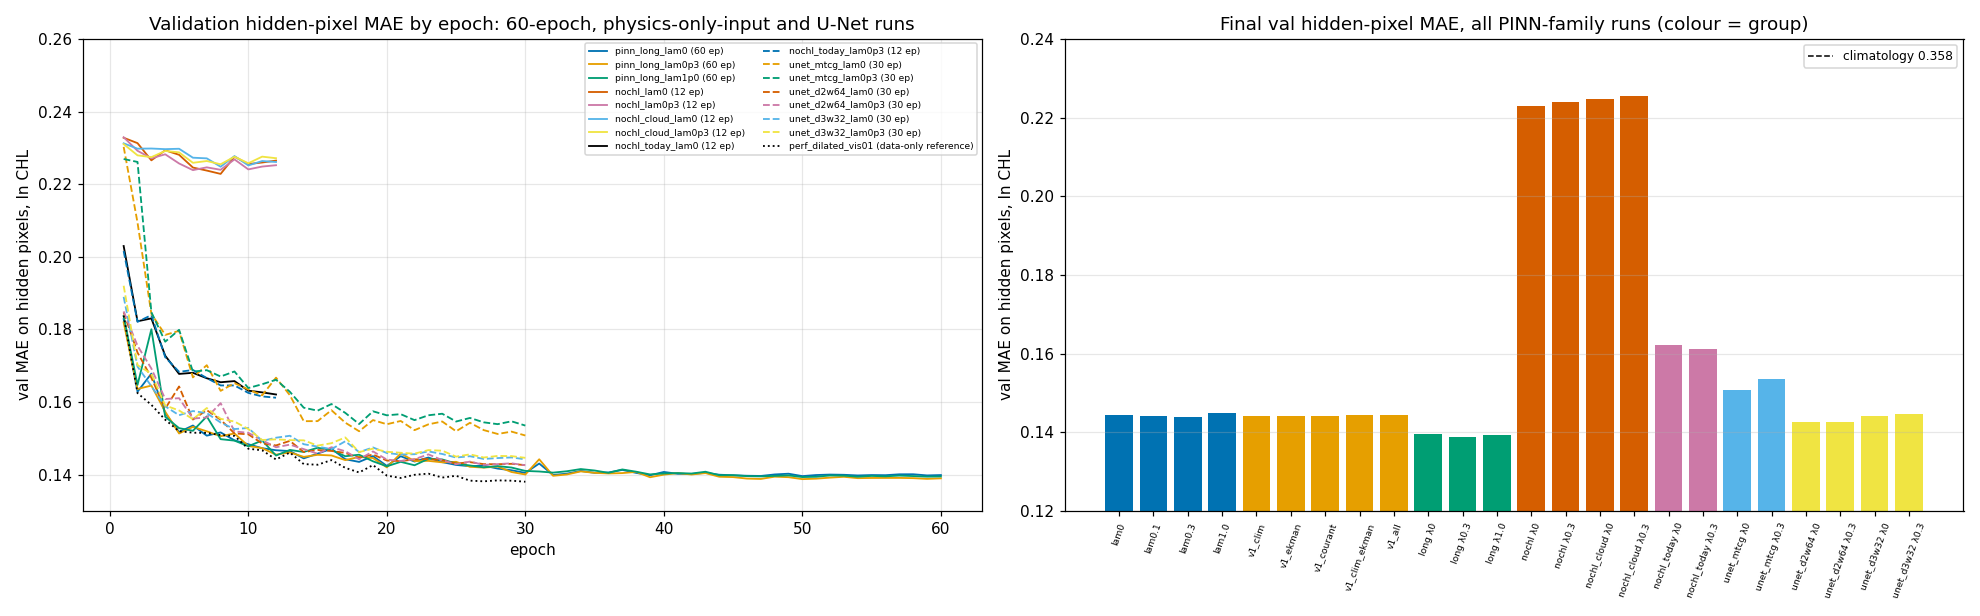

In [6]:
%run ../analyses/pinn/pinn_runs_summary.py
show(FIG / 'pinn_runs_summary.png', 1700)

**Observations.**

* 60 epochs: val MAE 0.1396 / 0.1388 / 0.1393 for λ = 0 / 0.3 / 1, spread 0.001 as at 12 epochs. All three sit above the 30-epoch data-only reference (0.1381). The residual under clouds at λ = 1 is 0.016, a quarter of the λ = 0 value.
* No CHL at any day: val MAE 0.223-0.226, R² 0.84-0.85, against climatology 0.358. Adding the observation masks does not help (0.2248 vs 0.2228), nor does the physics loss (0.2239 vs 0.2228).
* No CHL at t but CHL context at t±1 and physics at t−1..t+1: 0.162 (λ = 0) and 0.161 (λ = 0.3). The neighbouring-day CHL recovers three quarters of the gap between no-CHL (0.223) and the full image model (0.144).
* U-Net with the repo's inputs and MSE (4 features, CHL t±1), 30 epochs: 0.1508 at λ = 0, 0.1535 at λ = 0.3.
* The same 2-level U-Net with the full input set and L1: 0.1426 at both λ = 0 and λ = 0.3, so 0.008 of the earlier gap was inputs. It stays 0.002 behind the dilated CNN at 30 epochs (0.1405 in the 60-epoch run) with three times the parameters. The 3-level variant at equal size is 0.0016 worse (0.1442 / 0.1446). With the physics loss, the 2-level U-Net's residual under clouds falls from 0.066 to 0.029 at unchanged MAE.

## 6. Clear-day fake clouds, 60-epoch models

Same check as in Section 4 for the 60-epoch λ = 0 / 0.3 / 1 models: hidden-pixel MAE by day cloudiness, gradient structure on hidden pixels of clear days (obs fraction ≥ 0.6), and maps of the two clearest val days.

val days 1458; days with obs frac >= 0.6: 53
obs frac bin   n days    lambda 0  lambda 0.3    lambda 1
0.0-0.1           201      0.1402      0.1402      0.1400
0.1-0.2           250      0.1442      0.1437      0.1435
0.2-0.3           280      0.1351      0.1345      0.1351
0.3-0.4           321      0.1379      0.1369      0.1373
0.4-0.5           239      0.1332      0.1323      0.1330
0.5-0.6           114      0.1243      0.1233      0.1231
0.6-0.7            48      0.1290      0.1280      0.1275
0.7-0.8             5      0.1237      0.1230      0.1220
0.8-1.0             0          <5          <5          <5



clear val days (obs frac >= 0.6): 53; hidden px with 4 observed neighbours: 253586
run          hidden MAE     bias  |grad| pred/truth  grad corr  mean cos(angle) n hidden px
lambda 0         0.1339  -0.0101              0.612      0.628            0.445      385290
lambda 0.3       0.1330  -0.0096              0.569      0.633            0.461      385290
lambda 1         0.1329  -0.0065              0.554      0.626            0.469      385290


figures -> /mnt/custom-file-systems/s3/shared/ecology/mind_the_chl_gap/analyses/figures


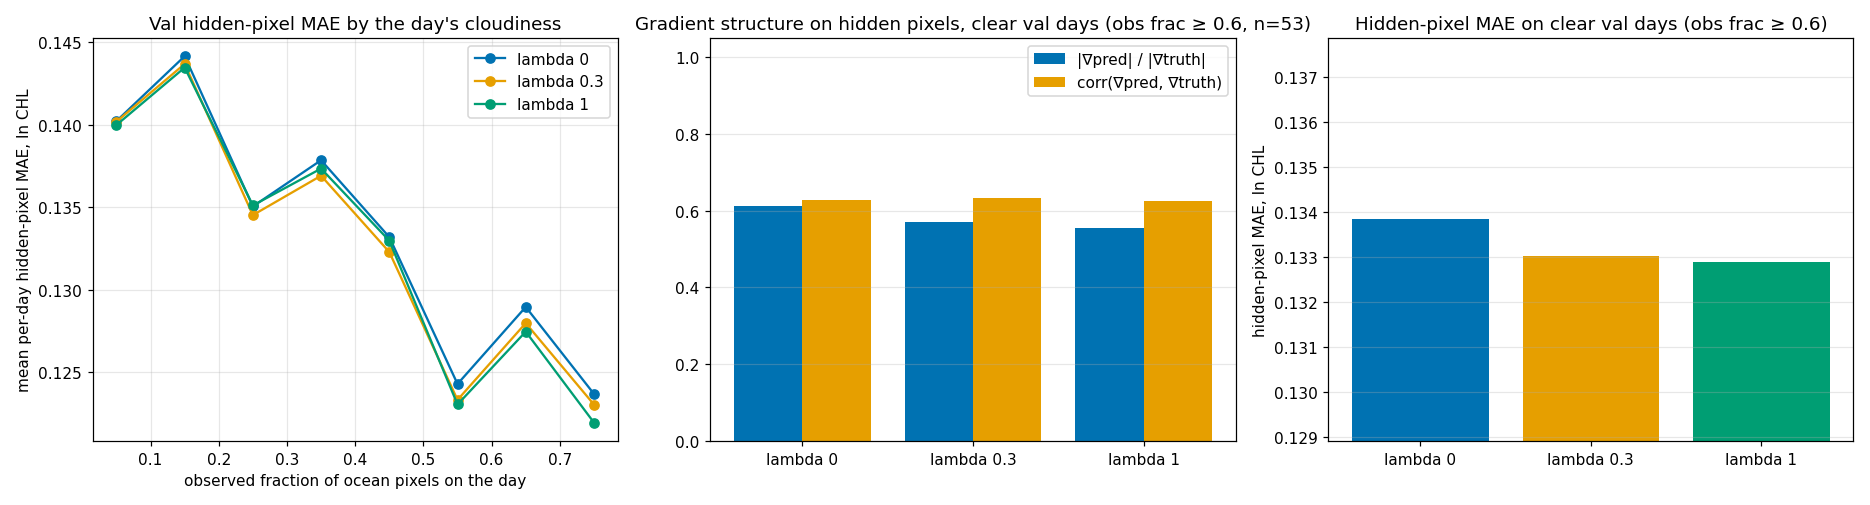

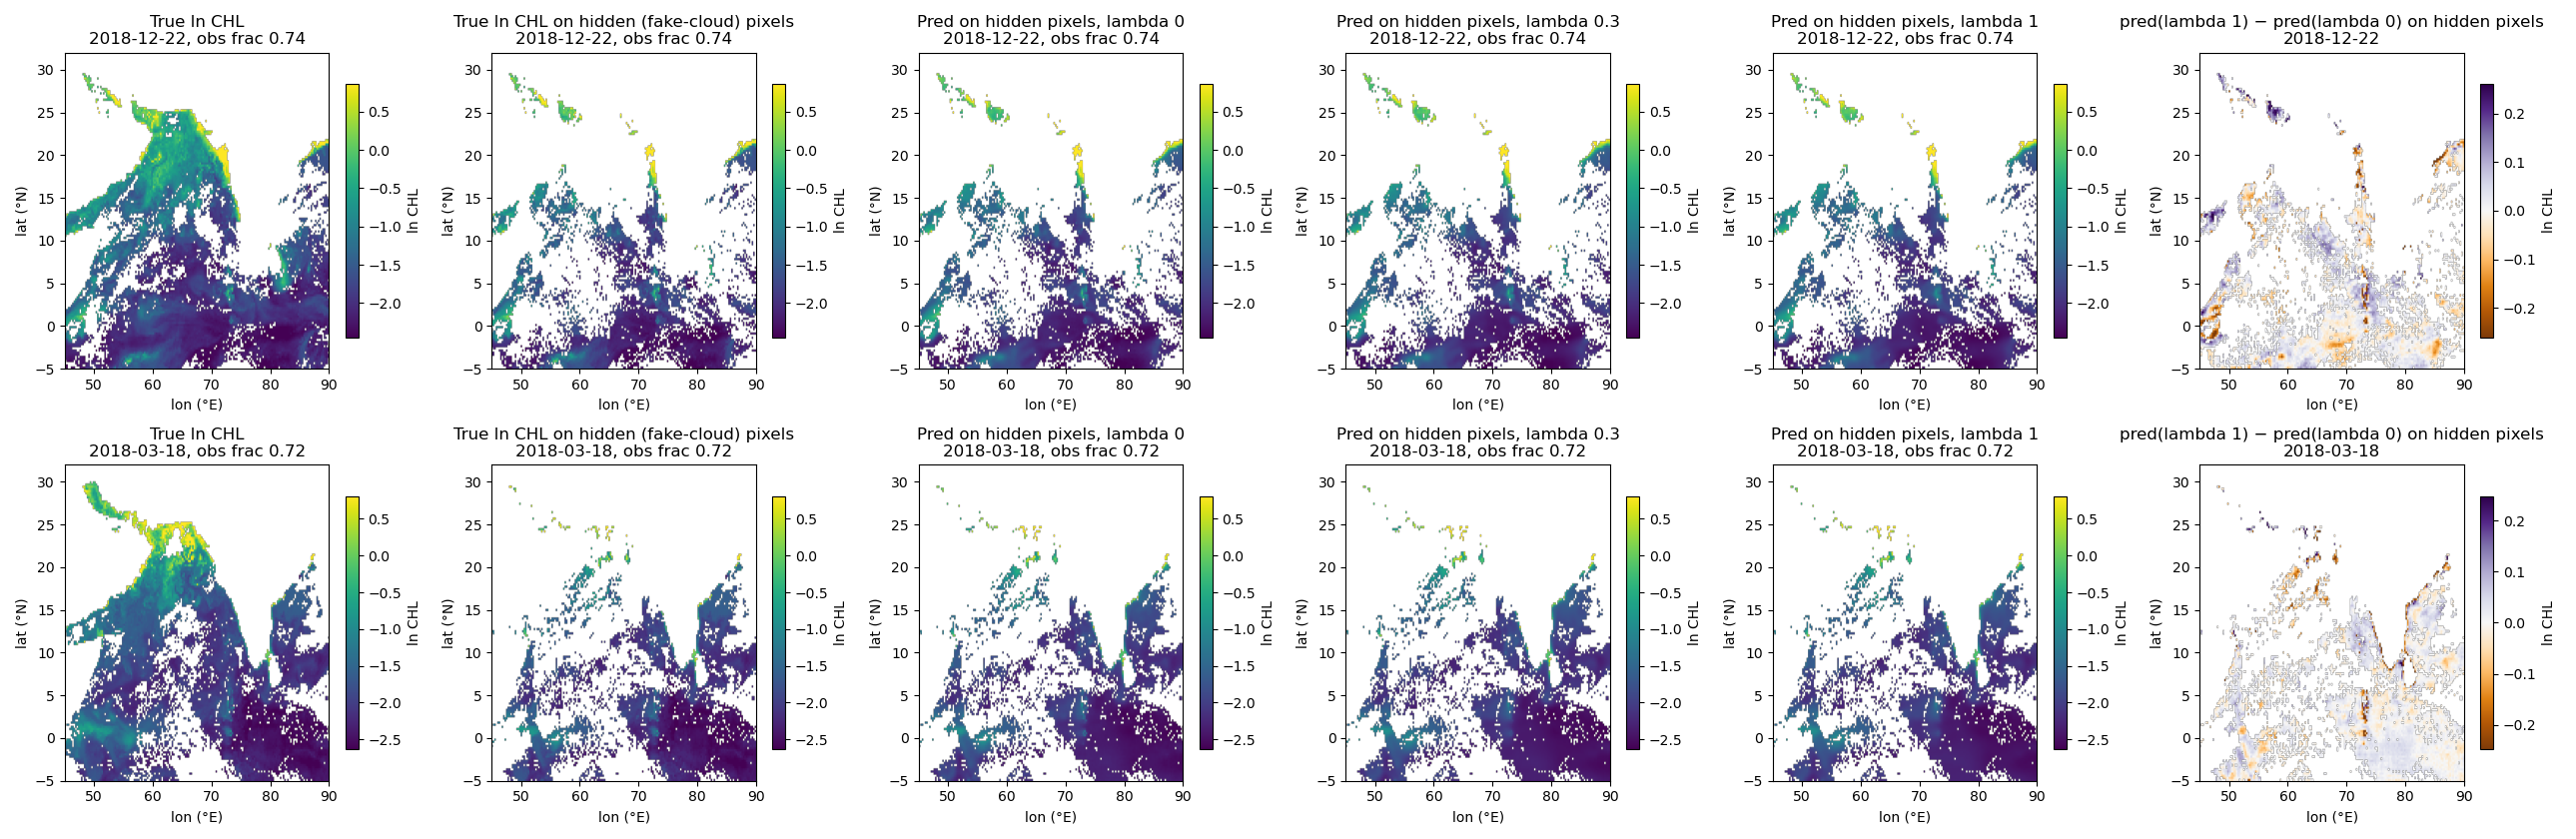

In [7]:
%run ../analyses/pinn/pinn_clear_days.py pinn_long_lam0 pinn_long_lam0p3 pinn_long_lam1p0
show(FIG / 'pinn_clear_structure_long.png')
show(FIG / 'pinn_clear_maps_long.png', 1800)

## 7. Does real cloud cover co-vary with the features?

Within-day comparison of each feature under real clouds vs on observed pixels (every 5th day, 1997-2020), and the real-cloud fraction by within-day feature decile.

days used 1693; mean real-cloud fraction 0.705
feature       mean dz (cloud - clear)   5th-95th pct over days  days dz>0  cloud frac decile1  decile10  n days
sst                             0.094       -0.56..      0.75       0.59               0.625     0.691    1692
air_temp                        0.035       -0.59..      0.67       0.54               0.620     0.677    1692
u_wind                          0.289       -0.34..      0.97       0.76               0.703     0.822    1692
v_wind                          0.060       -0.46..      0.65       0.54               0.733     0.748    1692
wind_speed                      0.394       -0.08..      0.92       0.91               0.597     0.822    1692
so                             -0.138       -0.60..      0.37       0.31               0.765     0.640    1692
sla                            -0.004       -0.37..      0.40       0.48               0.709     0.704    1691
mlotst                          0.104       -0.45..      0.56   

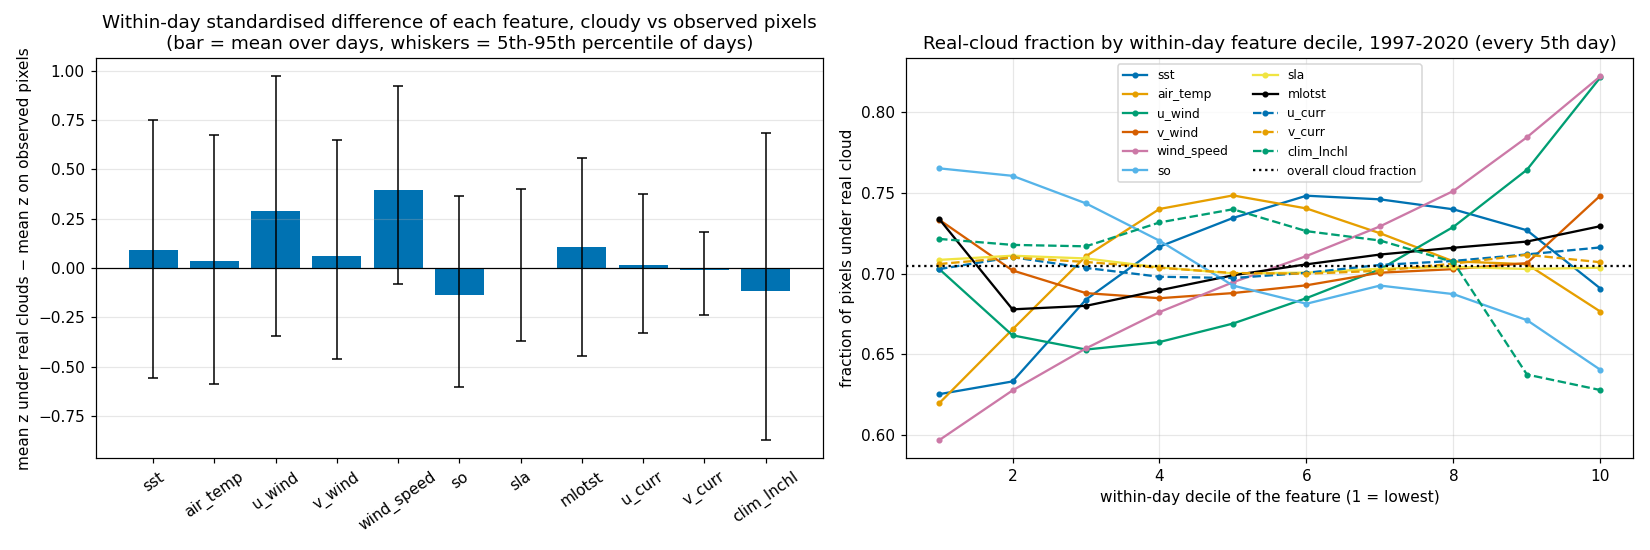

In [8]:
%run ../analyses/clouds/cloud_vs_features.py
show(FIGC / 'cloud_vs_features.png')

**Observations.** Cloudy pixels sit in stronger and more westerly wind (mean within-day z difference +0.39 and +0.29; cloud fraction 0.60 → 0.82 from the lowest to the highest wind-speed decile), in lower salinity (−0.14) and lower climatological CHL (−0.12). SST is non-monotone (cloud fraction peaks in the middle deciles). Air temperature, meridional wind, SLA and the currents are flat. "Real cloud" here is any missing L3 pixel, which includes glint, aerosol and swath gaps.

## 8. Summary

* Hidden-pixel MAE is flat across λ, across every prior, and at 12 and 60 epochs: the spread is 0.001 on a single seed. The physics term changes what is predicted under real clouds (0.05-0.06 ln CHL), where nothing is scored, by smoothing; the residual can be driven down fourfold without the field following the currents more closely (corr ≈ 0.08 at every λ).
* The two prior source terms are an order of magnitude below the residual; the optimiser switches the Ekman source off.
* Without the CHL image the model reaches 0.223 from the physical fields, climatology and coordinates alone, against 0.358 for climatology and 0.139-0.144 with the image. The physics loss and the cloud masks do not change that.
* A U-Net of the repo's size with our inputs reaches 0.1426 at 30 epochs, 0.002 behind the dilated CNN with 3× the parameters; the physics loss leaves its MAE unchanged while halving the residual under clouds. The repo's own input set costs a further 0.008.
* Without the CHL image at t but with the neighbouring days' CHL and physics, the model reaches 0.16.

Open questions: whether the Arabian Sea negative residual bias is in the data (compute the residual on fully observed consecutive-day pairs, no model); the seed-to-seed spread of the val MAE; whether the hidden-pixel score, binned by gap size and context-day cloudiness, hides a trade-off the aggregate cancels.